# Read Classification Comparison for WGBS PDX models from Achinger-Kawecka et al. 2024

Compares ICRG, bamcmp, and Xengsort read assignments across 8 PDX samples.

## 0. Imports and paths

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import *
from warnings import simplefilter
simplefilter("ignore")

In [2]:
results_dir = Path.cwd() / "results"
fig_dir = Path.cwd() / "figures" / "read_sorting"
fig_dir.mkdir(exist_ok = True, parents=True)

## 1. Load evaluation TSVs

In [3]:
icrg   = load_method(results_dir / "icrg_wgbs",   "icrg")
bamcmp = load_method(results_dir / "bamcmp_wgbs",  "bamcmp")
xengsort = load_method(results_dir / "xengsort_wgbs_newindex", "xengsort")
xengsort = xengsort[xengsort["Category"] != "sites"]
xengsort["Reads"] = xengsort["Reads"] * 2
xengsort["Sample"] = xengsort["Sample"].str.split("_0").apply(lambda x: x[0])

## 2. Read sorting outcomes per method

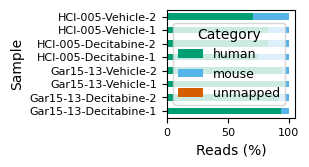

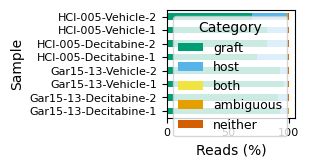

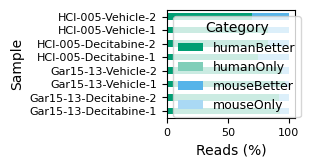

In [24]:
for suffix in ["pdf"]:
    icrg_pivot_pct = stacked_barplot(icrg, fig_dir = fig_dir, file_name = f"icrg_stacked_barplot_pct.{suffix}", save = True, figsize=mm_to_inches((80, 45)), colors = category_colors)
    xengsort_pivot_pct = stacked_barplot(xengsort, fig_dir = fig_dir, file_name = f"xengsort_stacked_barplot_pct.{suffix}", save = True, figsize=mm_to_inches((80, 45)), colors = category_colors, )
    bamcmp_pivotWhe_pct = stacked_barplot(bamcmp, fig_dir = fig_dir, file_name = f"bamcmp_stacked_barplot_pct.{suffix}", save = True,figsize=mm_to_inches((80, 45)), colors = category_colors)

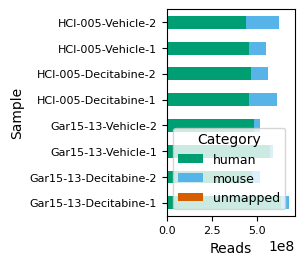

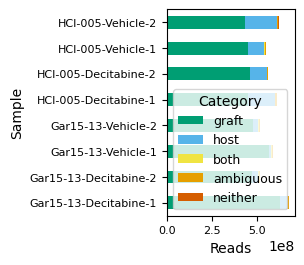

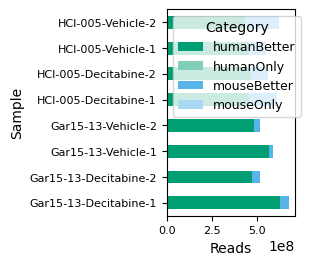

In [5]:
icrg_pivot = stacked_barplot(icrg, fig_dir = fig_dir, file_name = "icrg_stacked_barplot.pdf", percent = False, save = True, figsize=mm_to_inches((80, 70)), colors = category_colors)
xengsort_pivot = stacked_barplot(xengsort, fig_dir = fig_dir, file_name = "xengsort_stacked_barplot.pdf", percent = False, save = True, figsize=mm_to_inches((80, 70)), colors = category_colors, )
bamcmp_pivot = stacked_barplot(bamcmp, fig_dir = fig_dir, file_name = "bamcmp_stacked_barplot.pdf", percent = False, save = True,figsize=mm_to_inches((80, 70)), colors = category_colors)

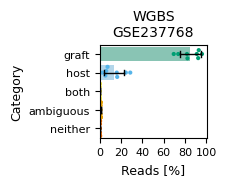

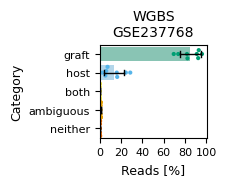

In [6]:
plot_xengsort_summary(xengsort,percent=True, figsize=mm_to_inches((60, 50)), size=3, legend=False, save=True, figure_dir=fig_dir, file_name="xengsort_pdx_summary.pdf", xticks = [0, 20, 40, 60, 80, 100],title="WGBS\nGSE237768")
plot_xengsort_summary(xengsort,percent=True, figsize=mm_to_inches((60, 50)), size=3, legend=False, save=True, figure_dir=fig_dir, file_name="xengsort_pdx_summary.png", xticks = [0, 20, 40, 60, 80, 100],title="WGBS\nGSE237768");